# Entregable II — Reducción de dimensión: PCA y UMAP (20 %)

**Proyecto:** Predicción de la intención de compra de usuarios en línea mediante aprendizaje supervisado.
**Curso:** Modelos y Simulación de Sistemas II — Universidad de Antioquia.

Este notebook reproduce la comparación de PCA y UMAP con la línea base de Random Forest
y la MLP. La reducción se ajusta dentro del `Pipeline`, solo con el 60 % de entrenamiento,
y se evalúa en validación y prueba.

> **Nota de tiempo:** `RECALCULAR = True` reajusta PCA y UMAP y puede tardar varios
> minutos. Con `False` se leen las tablas y figuras guardadas en `resultados_corregidos/`.

In [1]:
import os
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "src"))

import json
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("Directorio de trabajo:", RAIZ)

RECALCULAR = False  # True para reajustar PCA/UMAP desde el CSV

Directorio de trabajo: C:\proyectos-git\proyecto-modelos-2-prediccion-intencion-compra


## 1. Línea base

Random Forest y la MLP con los hiperparámetros ganadores de la sección del 30 %.

In [2]:
base = pd.read_csv("resultados_corregidos/metricas_particiones.csv")
base[(base.particion == "test") & (base.modelo.isin(["RandomForest", "MLP"]))][
    ["modelo", "AP", "ROC_AUC", "F1", "precision", "recall"]
].round(4)

,modelo,AP,ROC_AUC,F1,precision,recall
2,RandomForest,0.7486,0.9242,0.5904,0.8054,0.4660
5,MLP,0.7377,0.9270,0.6504,0.7220,0.5916


## 2. PCA: varianza acumulada

PCA retiene 28 componentes para el 95 % de la varianza: 61,64 % menos columnas que las
73 originales. El primer componente concentra 31,09 % de la varianza.

In [3]:
var = pd.read_csv("resultados_corregidos/pca_varianza.csv")
var.tail(8).round(4)

,componente,varianza_explicada,varianza_acumulada
20,21,0.0064,0.9184
21,22,0.0060,0.9243
22,23,0.0055,0.9299
23,24,0.0052,0.9351
24,25,0.0050,0.9401
25,26,0.0046,0.9447
26,27,0.0044,0.9491
27,28,0.0042,0.9534


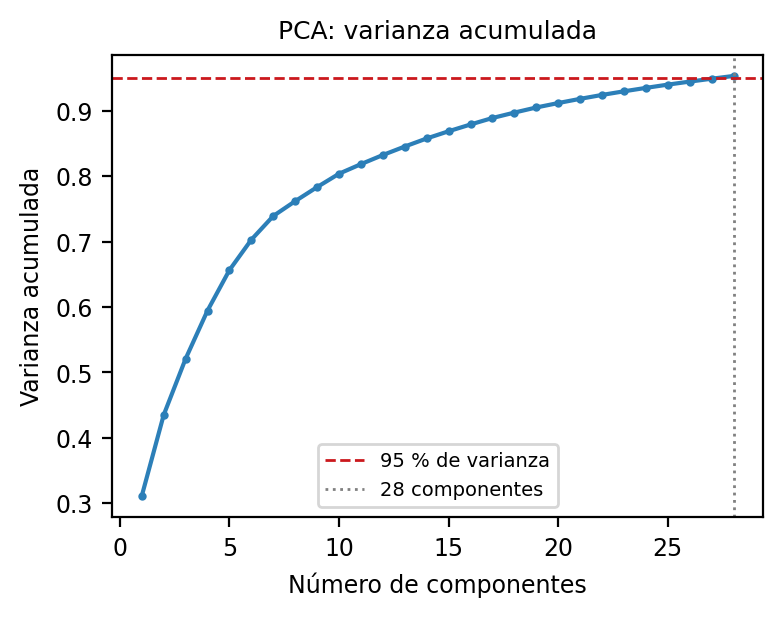

In [4]:
display(Image(filename="informe_entregable_II_latex/figuras/fig11_pca_varianza.png"))

## 3. Comparación PCA, UMAP y línea base

La tabla `reduccion_comparacion.csv` contiene AP, ROC-AUC, F1, reducción porcentual y
las diferencias frente a la base para PCA y UMAP de 10 componentes. `reduccion_umap2.csv`
contiene la variante de 2 componentes usada para visualización.

In [5]:
comp = pd.read_csv("resultados_corregidos/reduccion_comparacion.csv")
comp[comp.particion == "test"][
    ["modelo", "AP", "ROC_AUC", "F1", "reduccion_pct",
     "AP_base", "delta_AP", "delta_ROC_AUC", "delta_F1", "tiempo_seg"]
].round(4)

,modelo,AP,ROC_AUC,F1,reduccion_pct,AP_base,delta_AP,delta_ROC_AUC,delta_F1,tiempo_seg
1,PCA-RandomForest,0.7352,0.9226,0.6254,61.6438,0.7486,-0.0134,-0.0015,0.0350,6.96
3,PCA-MLP,0.7211,0.9220,0.6400,61.6438,0.7377,-0.0165,-0.0050,-0.0104,0.38
5,UMAP10-RandomForest,0.6650,0.8923,0.5896,86.3014,0.7486,-0.0836,-0.0319,-0.0008,48.12
7,UMAP10-MLP,0.6236,0.8571,0.6003,86.3014,0.7377,-0.1141,-0.0699,-0.0501,11.16


In [6]:
u2 = pd.read_csv("resultados_corregidos/reduccion_umap2.csv")
u2[u2.particion == "test"][
    ["modelo", "AP", "ROC_AUC", "F1", "tiempo_seg"]
].round(4)

,modelo,AP,ROC_AUC,F1,tiempo_seg
1,UMAP2-RandomForest,0.6489,0.8876,0.5839,11.16
3,UMAP2-MLP,0.5762,0.8504,0.5634,8.82


## 4. Figuras de la reducción

(a) Varianza acumulada de PCA y (b) AP de prueba con cada representación. La proyección
UMAP 2D se muestra aparte.

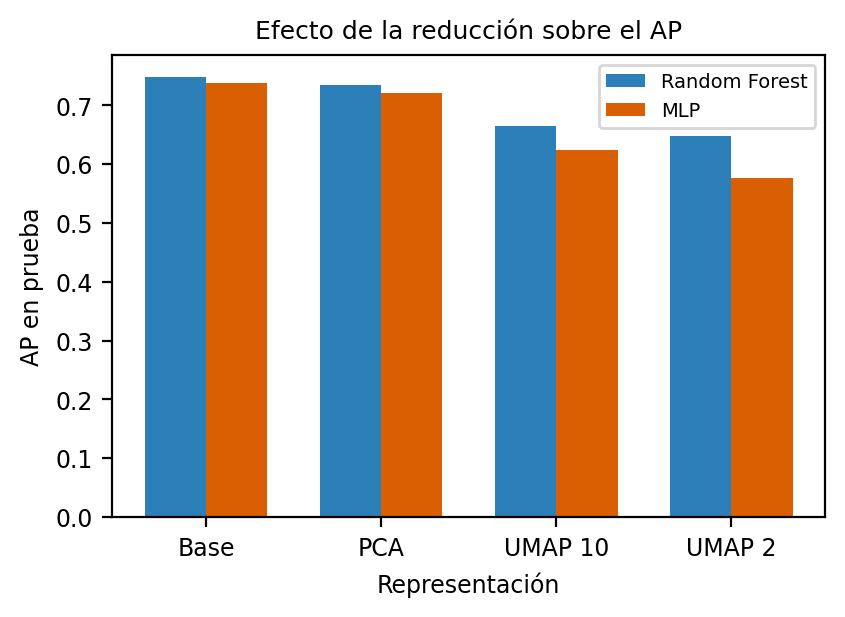

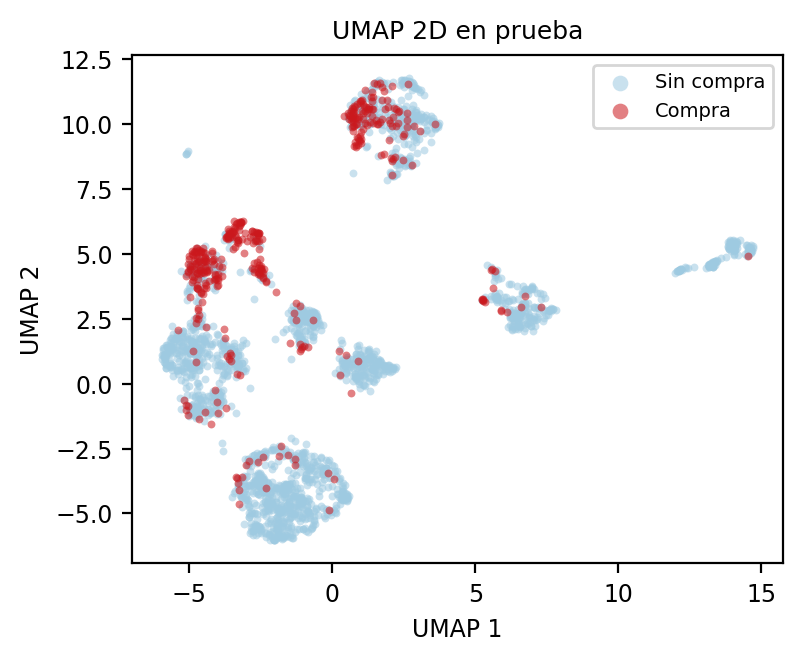

In [7]:
display(Image(filename="informe_entregable_II_latex/figuras/fig13_comparacion_reduccion.png"))
display(Image(filename="informe_entregable_II_latex/figuras/fig12_umap_2d.png"))

## 5. Recalcular desde el CSV (opcional)

Si `RECALCULAR = True`, se reajustan PCA y UMAP con la misma partición y semilla del
informe. Los resultados se sobrescriben en `resultados_corregidos/`.

In [8]:
if RECALCULAR:
    import reduccion
    reduccion.main()
    import figuras_reduccion  # el módulo genera las figuras al importarse
else:
    print("Se cargan los resultados guardados. Cambie RECALCULAR = True para reajustar.")

Se cargan los resultados guardados. Cambie RECALCULAR = True para reajustar.


## 6. Lectura de resultados

- PCA conserva el AP dentro de 1,7 puntos (RF 0,7352; MLP 0,7211) con 61,64 % menos
  columnas; el ROC-AUC se mantiene por encima de 0,92.
- UMAP de 10 componentes reduce 86,30 % de las columnas pero baja el AP a 0,6650 (RF) y
  0,6236 (MLP); con 2 componentes cae aún más.
- UMAP preserva vecindades locales, no la dirección lineal que separa las compras; su
  uso queda para visualización, no para el modelo final.